In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.9/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.9/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
from pyCRLD.Environments.TwoArmedBandit import TwoArmedBandit
from pyCRLD.Environments.DistTwoArmedBanditOneState import DistTwoArmedBanditOneState
from pyCRLD.Agents.StrategySARSA import stratSARSA
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA

from pyCRLD.Utils.PhasePlot import phaseplot, _data_to_plot, _strategies, _dXisa_s
import numpy as np

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl

## Poor environment

In [ ]:
env3s = TwoArmedBandit(rew=1, pun=-1, pA=0.3, pB=0.1)

In [ ]:
xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.7, 0.3],
               [0.9, 0.1]])
env1s = DistTwoArmedBanditOneState(disttype='discrete', xs=xs, ps=ps)

In [ ]:
quantiles = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30,
             0.35, 0.40, 0.45, 0.50, 0.55, 0.60,
             0.65, 0.70, 0.75, 0.80, 0.85, 0.90,
             0.95]

In [ ]:
dist_xinf3s = np.zeros((len(quantiles)))
dist_xinf1s = np.zeros((len(quantiles)))

In [ ]:
for i, q in enumerate(quantiles):
    mae3s = qbaseSARSA(env3s, nr_reward_bins=29, discretization_sigma=0.1, 
                       learning_rates=0.1, discount_factors=0, 
                       choice_intensities=4, Rmin=-2, Rmax=2,
                       quantile=q, use_prefactor=False)
    X = 0.5 * np.ones((1, 3, 2))
    traj, fpreached = mae3s.trajectory(X, 150)
    q_xinf = traj[-1, 0, 0, 0]
    dist_xinf3s[i] = q_xinf

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [ ]:
for i, q in enumerate(quantiles):
    mae1s = qbaseSARSA(env1s, nr_reward_bins=29, discretization_sigma=0.1, 
                       learning_rates=0.1, discount_factors=0, 
                       choice_intensities=4, Rmin=-2, Rmax=2,
                       quantile=q, use_prefactor=False)
    X = 0.5 * np.ones((1, 1, 2))
    traj, fpreached = mae1s.trajectory(X, 150)
    q_xinf = traj[-1, 0, 0, 0]
    dist_xinf1s[i] = q_xinf

Text(0.5, 1.0, 'Final strategy as a function of quantile')

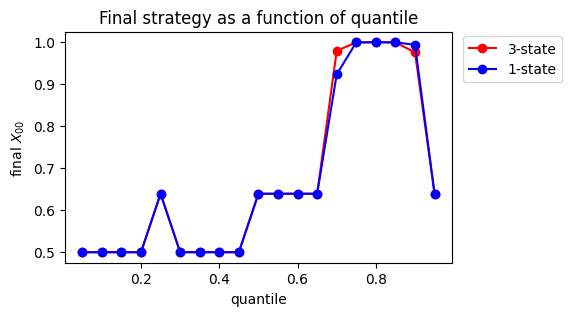

In [ ]:
# Plot
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax.plot(quantiles, dist_xinf3s, '-o', color='red', label="3-state")
ax.plot(quantiles, dist_xinf1s, '-o', color='blue', label="1-state")
ax.legend(bbox_to_anchor=(1.01, 1.01))
ax.set_xlabel("quantile")
ax.set_ylabel("final "+r'$X_{00}$')
ax.set_title("Final strategy as a function of quantile")

## Rich environment

In [ ]:
env3s = TwoArmedBandit(rew=1, pun=-1, pA=0.9, pB=0.7)

In [ ]:
xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.1, 0.9],
               [0.3, 0.7]])
env1s = DistTwoArmedBanditOneState(disttype='discrete', xs=xs, ps=ps)

In [ ]:
for i, q in enumerate(quantiles):
    mae3s = qbaseSARSA(env3s, nr_reward_bins=29, discretization_sigma=0.1, 
                       learning_rates=0.1, discount_factors=0, 
                       choice_intensities=4, Rmin=-2, Rmax=2,
                       quantile=q, use_prefactor=False)
    X = 0.5 * np.ones((1, 3, 2))
    traj, fpreached = mae3s.trajectory(X, 150)
    q_xinf = traj[-1, 0, 0, 0]
    dist_xinf3s[i] = q_xinf

In [ ]:
for i, q in enumerate(quantiles):
    mae1s = qbaseSARSA(env1s, nr_reward_bins=29, discretization_sigma=0.1, 
                       learning_rates=0.1, discount_factors=0, 
                       choice_intensities=4, Rmin=-2, Rmax=2,
                       quantile=q, use_prefactor=False)
    X = 0.5 * np.ones((1, 1, 2))
    traj, fpreached = mae1s.trajectory(X, 150)
    q_xinf = traj[-1, 0, 0, 0]
    dist_xinf1s[i] = q_xinf

Text(0.5, 1.0, 'Final strategy as a function of quantile')

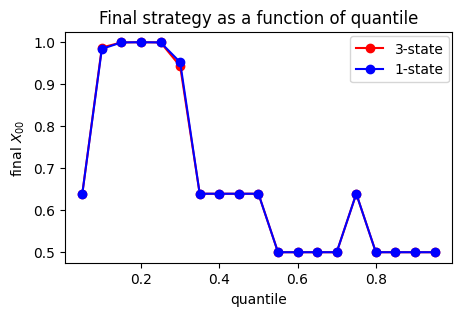

In [ ]:
# Plot
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax.plot(quantiles, dist_xinf3s, '-o', color='red', label="3-state")
ax.plot(quantiles, dist_xinf1s, '-o', color='blue', label="1-state")
ax.legend(bbox_to_anchor=(1.01, 1.01))
ax.set_xlabel("quantile")
ax.set_ylabel("final "+r'$X_{00}$')
ax.set_title("Final strategy as a function of quantile")